# Retail Driver Analysis — Promotion Activity vs. Sales

## Business Objective

Investigate the relationship between promotional activity and retail sales across store, product-family, and date combinations.

## Data Source

`data/processed/train_standardized.csv`

## Analysis Period

January 2013 – July 2017 (55 complete months).

## Key Questions

1. How frequently do promotions occur?
2. Are average sales different between records with and without promotional activity?
3. Does the relationship vary across product families?
4. What limitations should stakeholders understand?

## Important Analytical Limitation

`onpromotion` represents the number of items on promotion, not the number of transactions or a discount percentage.

Observed relationships do not establish that promotions caused changes in sales.

In [1]:
from pathlib import Path
import pandas as pd

# Resolve project root when running from the notebook folder.
PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "data" / "processed").exists():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError("Project data folder not found.")
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data/processed/train_standardized.csv"

sales = pd.read_csv(
    DATA_PATH,
    usecols=["date", "store_nbr", "family", "sales", "onpromotion"],
    parse_dates=["date"]
)

sales = sales.loc[
    (sales["date"] >= "2013-01-01")
    & (sales["date"] < "2017-08-01")
].copy()

print("Records:", len(sales))
print("Product families:", sales["family"].nunique())
print("Stores:", sales["store_nbr"].nunique())

sales.head()

Records: 2974158
Product families: 33
Stores: 54


,date,store_nbr,family,sales,onpromotion
0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,2013-01-01,1,BABY CARE,0.0,0
2,2013-01-01,1,BEAUTY,0.0,0
3,2013-01-01,1,BEVERAGES,0.0,0
4,2013-01-01,1,BOOKS,0.0,0


## 1. Promotion Data Quality Validation

Before analyzing the relationship between promotional activity and sales, we must verify that the promotion field is suitable for analysis.

Validation checks:
- Missing promotion values
- Negative promotion counts
- Minimum and maximum promotion counts
- Number of records with and without promotions

**Business rule:** `onpromotion` is a count of promoted items, not a discount percentage or transaction count.

In [2]:
# Validate the onpromotion field.
promotion_validation = {
    "total_records": len(sales),
    "missing_values": sales["onpromotion"].isna().sum(),
    "negative_values": (sales["onpromotion"] < 0).sum(),
    "minimum": sales["onpromotion"].min(),
    "maximum": sales["onpromotion"].max(),
    "no_promotion_records": (sales["onpromotion"] == 0).sum(),
    "promotion_records": (sales["onpromotion"] > 0).sum(),
}

pd.Series(promotion_validation, name="value")

total_records           2974158
missing_values                0
negative_values               0
minimum                       0
maximum                     741
no_promotion_records    2374613
promotion_records        599545
Name: value, dtype: int64

## 2. Average Sales: Promotion vs. No Promotion

### Business Question

Do store–product-family–day records with promotional activity have higher average sales than records without promotional activity?

### Method

Create two groups:
- No Promotion: `onpromotion == 0`
- With Promotion: `onpromotion > 0`

Calculate:
1. Number of records
2. Total sales
3. Average sales per record
4. Percentage of records
5. Percentage of total sales

**Interpretation warning:** This is a descriptive comparison. Differences may reflect product mix, store characteristics, time trends, or seasonality rather than the causal effect of promotions.

In [3]:
# Classify records by promotion activity.
sales["promotion_group"] = sales["onpromotion"].gt(0).map({
    False: "No Promotion",
    True: "With Promotion"
})

# Calculate descriptive sales metrics.
promotion_comparison = (
    sales.groupby("promotion_group", as_index=False)
    .agg(
        records=("sales", "size"),
        total_sales=("sales", "sum"),
        average_sales=("sales", "mean")
    )
)

# Calculate percentage contributions.
promotion_comparison["record_share_pct"] = (
    promotion_comparison["records"] / len(sales) * 100
)

promotion_comparison["sales_share_pct"] = (
    promotion_comparison["total_sales"]
    / promotion_comparison["total_sales"].sum()
    * 100
)

# Display the comparison.
promotion_comparison.round(2)

,promotion_group,records,total_sales,average_sales,record_share_pct,sales_share_pct
0,No Promotion,2374613,3.773279e+08,158.90,79.84,35.56
1,With Promotion,599545,6.838838e+08,1140.67,20.16,64.44


In [4]:
# Confirm all records are represented.
assert promotion_comparison["records"].sum() == len(sales)

# Confirm both group percentages sum to 100%.
assert abs(
    promotion_comparison["record_share_pct"].sum() - 100
) < 0.000001

assert abs(
    promotion_comparison["sales_share_pct"].sum() - 100
) < 0.000001

# Confirm the group totals reconcile with the source.
assert abs(
    promotion_comparison["total_sales"].sum()
    - sales["sales"].sum()
) < 0.01

print("All promotion comparison validation checks passed.")

All promotion comparison validation checks passed.


## 3. Visualizing Average Sales by Promotion Activity

### Objective

Compare average sales per store–product-family–day record between promotional and non-promotional groups.

### Business Interpretation

The visualization shows an observed association, not the causal impact of promotions.

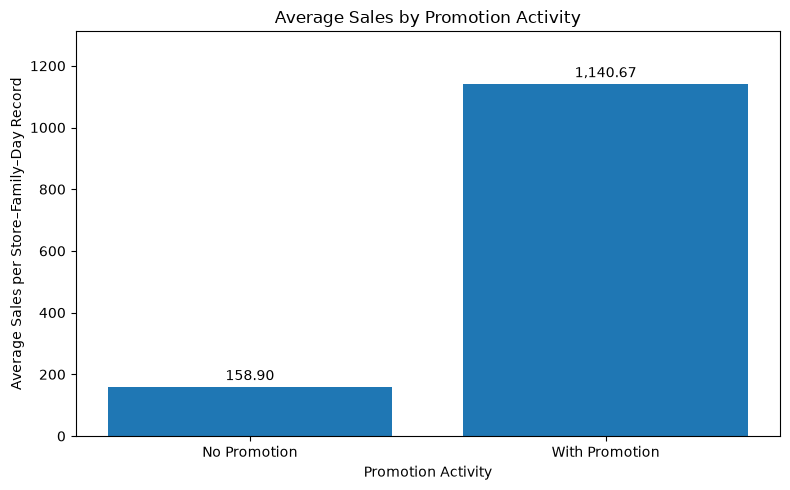

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    promotion_comparison["promotion_group"],
    promotion_comparison["average_sales"]
)

ax.set_title("Average Sales by Promotion Activity")
ax.set_xlabel("Promotion Activity")
ax.set_ylabel("Average Sales per Store–Family–Day Record")

for bar in bars:
    height = bar.get_height()

    ax.annotate(
        f"{height:,.2f}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

ax.set_ylim(
    0,
    promotion_comparison["average_sales"].max() * 1.15
)

plt.tight_layout()
plt.show()

## 4. Product-Family Promotion Analysis

### Business Question

Does the difference in average sales between promotional and non-promotional records vary across product families?

### Method

Group by:
- Product family
- Promotion activity

Calculate:
- Number of records
- Average sales
- Total sales

Then compare average sales within each family.

### Limitations

This controls descriptively for product family, but does not control for store, time, seasonality, or other confounding factors.

In [6]:
# Calculate sales metrics within each product family and promotion group.
family_promotion = (
    sales.groupby(
        ["family", "promotion_group"],
        as_index=False
    )
    .agg(
        records=("sales", "size"),
        total_sales=("sales", "sum"),
        average_sales=("sales", "mean")
    )
)

# Reshape to compare average sales side by side.
family_comparison = family_promotion.pivot(
    index="family",
    columns="promotion_group",
    values="average_sales"
)

# Calculate observed average sales ratio.
family_comparison["promotion_sales_ratio"] = (
    family_comparison["With Promotion"]
    / family_comparison["No Promotion"].replace(0, float("nan"))
)

# Display the highest-selling families first.
top_families = (
    sales.groupby("family")["sales"]
    .sum()
    .nlargest(10)
    .index
)

family_comparison.loc[top_families].round(2)

promotion_group,No Promotion,With Promotion,promotion_sales_ratio
family,,,
GROCERY I,2717.41,4408.65,1.62
BEVERAGES,1291.95,3211.60,2.49
PRODUCE,791.91,2442.38,3.08
CLEANING,868.32,1240.82,1.43
DAIRY,479.75,935.18,1.95
BREAD/BAKERY,379.14,576.49,1.52
POULTRY,312.79,486.49,1.56
MEATS,302.72,466.74,1.54
PERSONAL CARE,220.87,339.17,1.54


## 5. Product-Family Comparison Validation

### Objective

Check that the promotion comparison includes both promotional and non-promotional observations for each product family.

### Validation

1. Confirm the total number of product families.
2. Identify families missing either comparison group.
3. Calculate observation counts for each group.
4. Identify families with relatively small sample sizes.

### Business Importance

A large sales ratio based on very few observations may be unstable.

This analysis remains descriptive and does not establish causal promotion effects.

In [8]:
# Count observations by family and promotion group.
family_counts = (
    family_promotion.pivot(
        index="family",
        columns="promotion_group",
        values="records"
    )
    .reindex(
        columns=["No Promotion", "With Promotion"]
    )
    .fillna(0)
    .astype(int)
)

# Combine counts with average-sales comparison.
family_validation = family_counts.join(
    family_comparison[["promotion_sales_ratio"]]
)

family_validation["total_records"] = (
    family_validation["No Promotion"]
    + family_validation["With Promotion"]
)

family_validation["promotion_record_share_pct"] = (
    family_validation["With Promotion"]
    / family_validation["total_records"]
    * 100
)

print("Total families:", len(family_validation))

print(
    "Families missing a comparison group:",
    (
        (family_validation["No Promotion"] == 0)
        | (family_validation["With Promotion"] == 0)
    ).sum()
)

print("\nTop 10 families — sample-size validation:")

display(
    family_validation.loc[top_families].round(2)
)

Total families: 33
Families missing a comparison group: 1

Top 10 families — sample-size validation:


promotion_group,No Promotion,With Promotion,promotion_sales_ratio,total_records,promotion_record_share_pct
family,,,,,
GROCERY I,34047,56079,1.62,90126,62.22
BEVERAGES,39228,50898,2.49,90126,56.47
PRODUCE,60148,29978,3.08,90126,33.26
CLEANING,41033,49093,1.43,90126,54.47
DAIRY,44948,45178,1.95,90126,50.13
BREAD/BAKERY,51984,38142,1.52,90126,42.32
POULTRY,70658,19468,1.56,90126,21.60
MEATS,68785,21341,1.54,90126,23.68
PERSONAL CARE,52702,37424,1.54,90126,41.52


In [9]:
# Every source record must appear in exactly one family/group.
assert family_counts.to_numpy().sum() == len(sales)

# Family counts must match the source dataset.
assert len(family_validation) == sales["family"].nunique()

# No family should have a negative record count.
assert (family_counts >= 0).all().all()

print("Family-level record validation passed.")

Family-level record validation passed.


## 6. Investigation — Missing Promotion Comparison Group

### Data Quality Question

Which product family has no records in one of the promotion groups?

### Why This Matters

A promotional sales ratio requires both promotional and non-promotional observations.

If a family has no promotional records, its promotion-to-no-promotion ratio cannot be calculated.

We must identify the family and document the limitation rather than inventing a missing comparison value.

In [10]:
# Identify families missing either comparison group.
missing_comparison = family_validation.loc[
    (family_validation["No Promotion"] == 0)
    | (family_validation["With Promotion"] == 0)
]

print("Families requiring investigation:")

display(missing_comparison)

Families requiring investigation:


promotion_group,No Promotion,With Promotion,promotion_sales_ratio,total_records,promotion_record_share_pct
family,,,,,
BOOKS,90126,0,NaN,90126,0.0


In [11]:
# Investigate the affected family or families.
affected_families = missing_comparison.index.tolist()

affected_records = sales.loc[
    sales["family"].isin(affected_families)
]

investigation = (
    affected_records.groupby("family")
    .agg(
        records=("sales", "size"),
        total_sales=("sales", "sum"),
        average_sales=("sales", "mean"),
        min_promotion=("onpromotion", "min"),
        max_promotion=("onpromotion", "max"),
        promotion_records=(
            "onpromotion",
            lambda x: (x > 0).sum()
        )
    )
)

display(investigation.round(2))

,records,total_sales,average_sales,min_promotion,max_promotion,promotion_records
family,,,,,,
BOOKS,90126,6430.0,0.07,0,0,0


### Investigation Result — BOOKS

The BOOKS product family contains 90,126 records during the
55-month analysis period.

Findings:
- No Promotion records: 90,126
- With Promotion records: 0
- Total sales: 6,430.00
- Average sales per record: approximately 0.07
- Promotion sales ratio: Not Available (NaN)

**Conclusion:** BOOKS has no observed promotional activity in
the analyzed dataset. The comparison ratio is undefined because
there are no promotional observations.

**Data handling decision:** Retain BOOKS in the dataset and
preserve its missing comparison ratio. Do not replace NaN with zero.

**Limitation:** This finding describes the available dataset;
it does not prove that BOOKS was never promoted outside the
observed records or analysis period.

## 7. Product-Family Promotion Sales Comparison

### Business Objective

Compare average sales per store–family–day record with and
without promotional activity for the top 10 families by sales.

### Analytical Method

Use a grouped bar chart to compare the two promotion groups
within each product family.

### Important Limitation

These are observed average sales differences, not estimates
of the causal impact of promotions.

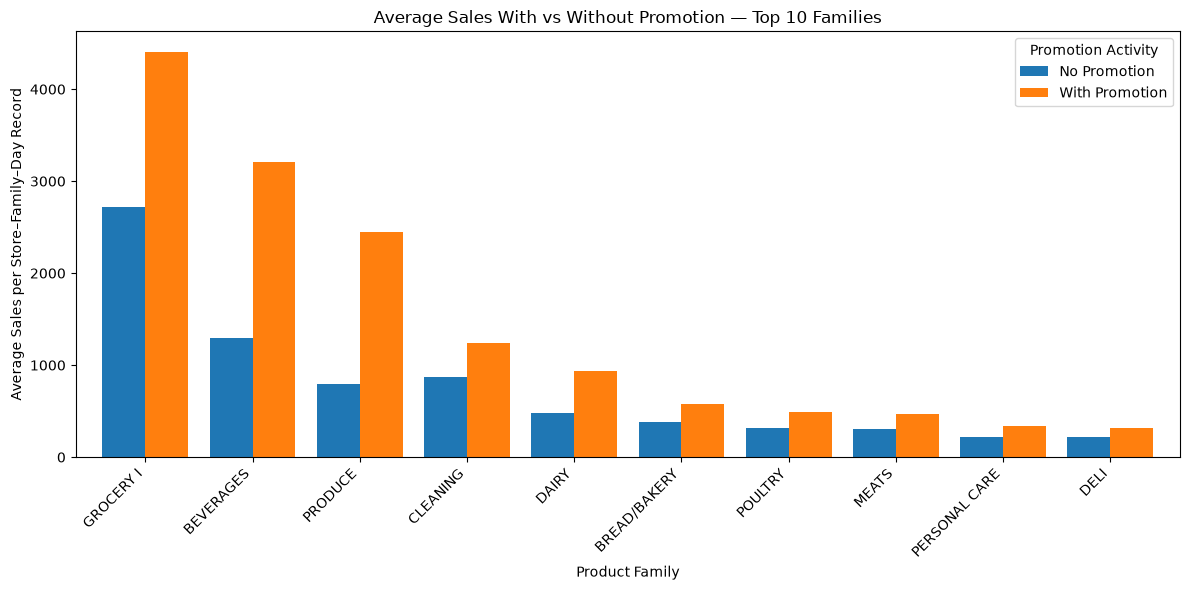

In [12]:
# Select the top 10 families by total sales.
chart_data = family_comparison.loc[
    top_families,
    ["No Promotion", "With Promotion"]
]

# Create a grouped bar chart.
ax = chart_data.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title(
    "Average Sales With vs Without Promotion — Top 10 Families"
)
ax.set_xlabel("Product Family")
ax.set_ylabel("Average Sales per Store–Family–Day Record")

ax.legend(title="Promotion Activity")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [13]:
# Confirm BOOKS is retained in the full analysis.
assert "BOOKS" in family_comparison.index

# Confirm its promotional comparison is undefined.
assert pd.isna(
    family_comparison.loc["BOOKS", "promotion_sales_ratio"]
)

# Confirm all selected chart families have valid ratios.
assert family_comparison.loc[
    top_families, "promotion_sales_ratio"
].notna().all()

print("Promotion comparison and chart validation passed.")

Promotion comparison and chart validation passed.


## 8. Export Validated Promotion Analysis

### Objective

Save the completed promotion analysis as CSV reports for:
- Business reporting
- Power BI integration
- Further forecasting analysis
- Reproducibility and GitHub documentation

### Outputs

1. Overall promotion sales comparison
2. Product-family promotion comparison

The product-family report retains BOOKS with an unavailable
promotion sales ratio because no promotional records were observed.

In [14]:
# Define the report directory.
REPORT_DIR = (
    PROJECT_ROOT
    / "reports"
    / "retail_driver_analysis"
)

REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Report 1: Overall promotion comparison.
overall_report = (
    REPORT_DIR
    / "promotion_sales_comparison.csv"
)

promotion_comparison.to_csv(
    overall_report,
    index=False
)

# Report 2: Product-family promotion comparison.
family_report = (
    REPORT_DIR
    / "product_family_promotion_comparison.csv"
)

family_export = (
    family_validation
    .reset_index()
)

family_export.to_csv(
    family_report,
    index=False
)

print("Saved:", overall_report)
print("Saved:", family_report)

Saved: d:\GitHub\retail-sales-forecasting\reports\retail_driver_analysis\promotion_sales_comparison.csv
Saved: d:\GitHub\retail-sales-forecasting\reports\retail_driver_analysis\product_family_promotion_comparison.csv


In [15]:
# Reload reports to verify saved content.
overall_check = pd.read_csv(overall_report)
family_check = pd.read_csv(family_report)

assert len(overall_check) == 2
assert len(family_check) == 33

assert overall_check["records"].sum() == len(sales)

# BOOKS must remain in the exported report.
books_check = family_check.loc[
    family_check["family"] == "BOOKS"
]

assert len(books_check) == 1
assert books_check["With Promotion"].iloc[0] == 0

assert pd.isna(
    books_check["promotion_sales_ratio"].iloc[0]
)

print("All exported report validation checks passed.")

All exported report validation checks passed.
